# Algoritmo de Dijkstra

Calcula las distancias mínimas desde un origen a todos los nodos de un grafo con pesos **no negativos**. Usa una cola de prioridad: extrae siempre el nodo más cercano aún no fijado y relaja sus aristas. Cuesta $O((V + E) \log V)$ con `heapq`.

Los grafos ponderados se representan como `nodo → {vecino: peso}`.

## 1. Distancias mínimas

Calcular la distancia mínima desde `A` a cada ciudad.

In [1]:
import heapq

grafo = {
    "A": {"B": 4, "C": 2},
    "B": {"C": 5, "D": 10},
    "C": {"E": 3},
    "D": {"F": 11},
    "E": {"D": 4},
    "F": {},
}

def dijkstra(grafo, origen):
    dist = {n: float("inf") for n in grafo}
    previo = {origen: None}
    dist[origen] = 0
    cola = [(0, origen)]
    while cola:
        d, n = heapq.heappop(cola)
        # entrada obsoleta, ya hay una mejor
        if d > dist[n]:
            continue
        for v, peso in grafo[n].items():
            if d + peso < dist[v]:
                dist[v], previo[v] = d + peso, n
                heapq.heappush(cola, (dist[v], v))
    return dist, previo

dist, previo = dijkstra(grafo, "A")
print(dist)

{'A': 0, 'B': 4, 'C': 2, 'D': 9, 'E': 5, 'F': 20}


## 2. Ruta más corta

Reconstruir la ruta más corta de `A` a `F` a partir de los predecesores.

In [2]:
def ruta(previo, destino):
    if destino not in previo:
        return None
    camino = []
    while destino is not None:
        camino.append(destino)
        destino = previo[destino]
    return camino[::-1]

print(ruta(previo, "F"), dist["F"])

['A', 'C', 'E', 'D', 'F'] 20


## 3. Red de metro con transbordos

En una red de metro inventada, cada nodo es un par `(estación, línea)`: viajar entre estaciones consecutivas de una línea cuesta los minutos del tramo, y cambiar de línea en una estación, 4 minutos de transbordo. Calcular con Dijkstra el trayecto más rápido entre dos estaciones (añadiendo un nodo ficticio de salida y otro de llegada), describirlo por tramos, comprobarlo contra Bellman-Ford para todos los pares de estaciones y dibujarlo.

20 minutos: L2: Aeropuerto → Catedral; transbordo en Catedral; L1: Catedral → Estadio
15 minutos: L1: Puerto → Catedral; transbordo en Catedral; L2: Catedral → Playa


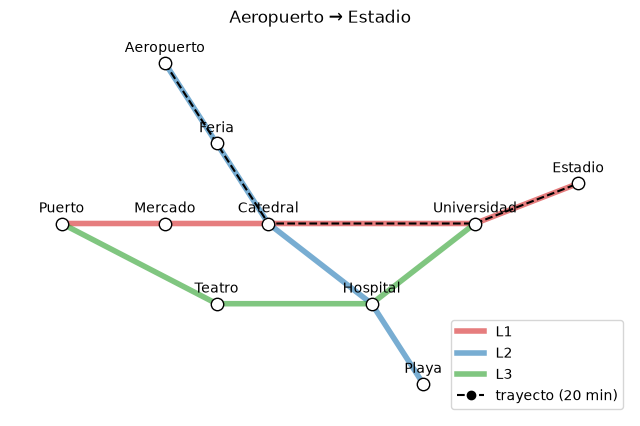

In [3]:
import matplotlib.pyplot as plt

lineas = {
    "L1": ["Puerto", "Mercado", "Catedral", "Universidad", "Estadio"],
    "L2": ["Aeropuerto", "Feria", "Catedral", "Hospital", "Playa"],
    "L3": ["Puerto", "Teatro", "Hospital", "Universidad"],
}
minutos = {"L1": [3, 2, 4, 3], "L2": [6, 3, 2, 4], "L3": [4, 4, 5]}
TRANSBORDO = 4
SALIDA, LLEGADA = ("salida", ""), ("llegada", "")

metro = {}
for linea, estaciones in lineas.items():
    for e in estaciones:
        metro.setdefault((e, linea), {})
    for (a, b), m in zip(zip(estaciones, estaciones[1:]), minutos[linea]):
        metro[a, linea][b, linea] = metro[b, linea][a, linea] = m
for e, l1 in metro.copy():
    for e2, l2 in metro.copy():
        if e == e2 and l1 != l2:
            metro[e, l1][e, l2] = TRANSBORDO

def trayecto(origen, destino):
    grafo = {n: dict(vecinos) for n, vecinos in metro.items()}
    grafo[SALIDA] = {n: 0 for n in metro if n[0] == origen}
    grafo[LLEGADA] = {}
    for n in metro:
        if n[0] == destino:
            grafo[n][LLEGADA] = 0
    dist, previo = dijkstra(grafo, SALIDA)
    return dist[LLEGADA], ruta(previo, LLEGADA)[1:-1], grafo

def describe(camino):
    pasos, inicio = [], camino[0]
    for anterior, actual in zip(camino, camino[1:] + [None]):
        if actual is None or actual[1] != anterior[1]:
            pasos.append(f"{inicio[1]}: {inicio[0]} → {anterior[0]}")
            if actual is not None:
                pasos.append(f"transbordo en {actual[0]}")
            inicio = actual
    return pasos

def bellman_ford(grafo, origen):
    dist = {n: float("inf") for n in grafo}
    dist[origen] = 0
    for _ in range(len(grafo) - 1):
        for u in grafo:
            for v, w in grafo[u].items():
                dist[v] = min(dist[v], dist[u] + w)
    return dist

total, camino_metro, grafo_metro = trayecto("Aeropuerto", "Estadio")
print(total, "minutos:", "; ".join(describe(camino_metro)))
print(trayecto("Puerto", "Playa")[0], "minutos:", "; ".join(describe(trayecto("Puerto", "Playa")[1])))

estaciones = sorted({e for e, _ in metro})
for a in estaciones:
    for b in estaciones:
        coste, _, g = trayecto(a, b)
        assert coste == bellman_ford(g, SALIDA)[LLEGADA]

posiciones = {"Puerto": (0, 2), "Mercado": (1, 2), "Catedral": (2, 2), "Universidad": (4, 2), "Estadio": (5, 2.5),
              "Aeropuerto": (1, 4), "Feria": (1.5, 3), "Hospital": (3, 1), "Playa": (3.5, 0),
              "Teatro": (1.5, 1)}
colores = {"L1": "tab:red", "L2": "tab:blue", "L3": "tab:green"}
fig, eje = plt.subplots(figsize=(8, 5))
for linea, ests in lineas.items():
    eje.plot(*zip(*(posiciones[e] for e in ests)), color=colores[linea], linewidth=4, alpha=0.6, label=linea)
eje.plot(*zip(*(posiciones[e] for e, _ in camino_metro)), color="black", linewidth=1.5, linestyle="--",
         marker="o", label=f"trayecto ({total} min)")
for e, (x, y) in posiciones.items():
    eje.scatter(x, y, s=80, color="white", edgecolor="black", zorder=3)
    eje.annotate(e, (x, y), xytext=(0, 8), textcoords="offset points", ha="center")
eje.legend(loc="lower right")
eje.set_title("Aeropuerto → Estadio")
eje.margins(0.1)
eje.axis("off")
plt.show()

## 4. Los k caminos más cortos

Permitir que cada nodo salga de la cola hasta k veces: la i-ésima vez que sale el destino se tiene el i-ésimo camino más corto. Si el grafo tiene ciclos, los caminos pueden repetir nodos; en un DAG siempre son caminos simples. Obtener los caminos de `A` a `F` y comprobar en DAG aleatorios que sus costes coinciden con los k menores al enumerar todos los caminos.

In [4]:
import random

def k_caminos(grafo, origen, destino, k):
    salidas = {n: 0 for n in grafo}
    cola, caminos = [(0, [origen])], []
    while cola and len(caminos) < k:
        d, camino = heapq.heappop(cola)
        n = camino[-1]
        if salidas[n] == k:
            continue
        salidas[n] += 1
        if n == destino:
            caminos.append((d, camino))
        for v, peso in grafo[n].items():
            heapq.heappush(cola, (d + peso, camino + [v]))
    return caminos

for d, camino in k_caminos(grafo, "A", "F", 5):
    print(d, camino)

def todos_los_caminos(grafo, n, destino):
    if n == destino:
        return [(0, [n])]
    return [(peso + d, [n] + resto) for v, peso in grafo[n].items() for d, resto in todos_los_caminos(grafo, v, destino)]

def dag_aleatorio(n, p):
    return {u: {v: random.randint(1, 9) for v in range(u + 1, n) if random.random() < p} for u in range(n)}

random.seed(6)
for _ in range(300):
    n = random.randint(2, 9)
    g = dag_aleatorio(n, 0.5)
    k = random.randint(1, 6)
    todos = sorted(d for d, _ in todos_los_caminos(g, 0, n - 1))
    assert [d for d, _ in k_caminos(g, 0, n - 1, k)] == todos[:k]

20 ['A', 'C', 'E', 'D', 'F']
25 ['A', 'B', 'D', 'F']
27 ['A', 'B', 'C', 'E', 'D', 'F']
